<font size="+3">Monitor : PD-1 duo designs</font>


In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import seaborn as sns
import shutil
import glob

from pandas.api.types import CategoricalDtype
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score


In [2]:
def plot_adjust_settings(xlabel, ylabel, ax=None):
    if ax is None:
        ax = plt.gca()
        
    ax.set_xlabel(xlabel,fontsize=11,labelpad=7)
    ax.set_ylabel(ylabel,fontsize=11,labelpad=7)
    ax.tick_params(labelsize=9, pad=5)
    

# PD-1 data layer

PD-L1 shipped `deltaG_labled.pkl` and `experimental_labels.csv`. PD-1 ships two
ΔG CSVs and a BLI summary instead, so this cell normalises it to the same schema
and every downstream cell works unchanged.

Label convention follows `Analysis/REPORT.md`: the `HuPDL1-Fc` natural-ligand
control is removed, a human binder is `Cross-reactive` or `Human-specific`, a
mouse binder is `Cross-reactive` or `Mouse-specific`, `Likely nonspecific/sticky`
counts as non-binding, and the borderline calls are dropped from the target they
are borderline for. That reproduces the report's 16/94, 12/93 and 9/95.


In [3]:
# ---- PD-1 data layer ----------------------------------------------------
PD1 = Path('.')

# 1. experimental labels, from the BLI summary ----------------------------
CONTROL_CLASS = 'Positive control (natural ligand)'   # HuPDL1-Fc, not a design
CLASS_TO_EXP = {
    'Cross-reactive':                'both',
    'Human-specific':                'human',
    'Mouse-specific':                'mouse',
    'Non-binding':                   'none',
    'Likely nonspecific/sticky':     'none',     # also binds lysozyme
    'Non-binding (no MuPD-1 data)':  'none',
    'Borderline (weak human trend)': 'unknown',
    'Borderline (weak mouse trend)': 'unknown',
}
BINDER_CLASS = {'human': {'Cross-reactive', 'Human-specific'},
                'mouse': {'Cross-reactive', 'Mouse-specific'}}
EXCLUDE_TARGET = {'human': {'Borderline (weak human trend)'},
                  'mouse': {'Borderline (weak mouse trend)',
                            'Non-binding (no MuPD-1 data)'}}
TARGETS = ['human', 'mouse']

summary = pd.read_csv(PD1 / 'PD1_duo_DesignSummary.csv', sep=';', decimal=',')
summary = summary.rename(columns={'EPFL Name': 'Design'})
summary = summary[summary.Classification != CONTROL_CLASS].copy()
summary['Experimental'] = summary.Classification.map(CLASS_TO_EXP)
anno = summary[['Design', 'Experimental']]

anno_long = pd.concat([
    pd.DataFrame({'Design': s.Design, 'target': t,
                  'binary': np.where(s.Classification.isin(BINDER_CLASS[t]),
                                     'binder', 'decoy')})
    for t in TARGETS
    for s in [summary[~summary.Classification.isin(EXCLUDE_TARGET[t])]]
], ignore_index=True)

def add_binary(df):
    """Attach Experimental + binder/decoy, honouring the per-target exclusions."""
    df = df.merge(anno_long, on=['Design', 'target'], how='inner')
    return df.merge(anno, on='Design', how='left')

def add_group(df):
    """cross-reactive vs single/none, for the worst-target panels."""
    df = df.merge(anno, how='left', on='Design')
    df = df[df['Experimental'] != 'unknown'].copy()
    df['group'] = np.where(df['Experimental'].eq('both'), 'cross-reactive', 'single/none')
    return df

# 2. MD ΔG: two CSVs; mouse binder names carry a trailing _m --------------
def _read_md(path, target):
    d = pd.read_csv(path, index_col=0)
    d['Design'] = d.binder.str.replace(r'_m$', '', regex=True)
    return d.assign(target=target)[['Design', 'target', 'rep', 'deltaG']]

md_all = pd.concat([_read_md(PD1 / 'PD1_Human_deltaG.csv', 'human'),
                    _read_md(PD1 / 'PD1_Mouse_deltaG.csv', 'mouse')], ignore_index=True)
md_all = md_all.merge(anno, on='Design', how='left')
md_all['binder'] = md_all['Design']                      # kept for older cells
md_all['batch']  = np.where(md_all.Experimental.eq('none'), 'decoys', 'binders')

# 3. predictors -----------------------------------------------------------
# All four now share one layout, the same one the PD-L1 notebook reads:
#     <root>/<hPD1|mPD1>/output.csv
# with three seeds per design and ipTM in column 'iptm'. The seeds are averaged
# to one value per (design, target), exactly as for PD-L1, so the two campaigns
# are directly comparable. Only output.csv is read; the mmCIF models under
# output/models/ are never touched.
#
# The earlier single-model ESMFold2 and Protenix-v2 runs are kept in
# ESMFold2_LN/ and Protenix-V2_LN/ and are deliberately NOT used here.
PRED       = {'AF3': 'AF3', 'ESMFold2': 'ESMFold2',
              'Protenix-v2': 'Protenix-v2', 'OpenDDE': 'OpenDDE'}
TARGET_DIR = {'human': 'hPD1', 'mouse': 'mPD1'}

def pred_path(name, target):
    return PD1 / PRED[name] / TARGET_DIR[target] / 'output.csv'

def has_pred(name):
    return all(pred_path(name, t).exists() for t in TARGETS)

METHODS = ['MD'] + [m for m in ['AF3', 'ESMFold2', 'Protenix-v2', 'OpenDDE'] if has_pred(m)]

# MD exists for only a subset of the designs. Keep this True so every method is
# scored on the same designs; set it False to score the predictors on all 95.
RESTRICT_TO_MD = True
MD_DESIGNS = set(md_all.Design)

def read_pred(name, target):
    """One ipTM per design and target, averaged over the seeds."""
    d = (pd.read_csv(pred_path(name, target)).rename(columns={'ID': 'Design'})
           .groupby('Design', as_index=False)
           .agg(iptm=('iptm', 'mean'), iptm_sd=('iptm', 'std'), n_models=('iptm', 'size')))
    if RESTRICT_TO_MD:
        d = d[d.Design.isin(MD_DESIGNS)]
    return d.assign(target=target)

def load_iptm(name):
    """Long form: one ipTM per design and target, with the binder/decoy label."""
    d = pd.concat([read_pred(name, t) for t in TARGETS], ignore_index=True)
    return add_binary(d[['Design', 'target', 'iptm']])

def load_iptm_min(name):
    """Wide form: worst of the two targets, for the cross-reactivity panels."""
    w = {t: read_pred(name, t)[['Design', 'iptm']].rename(columns={'iptm': f'iptm_{t[0]}'})
         for t in TARGETS}
    df = w['human'].merge(w['mouse'], on='Design')
    df = add_group(df)
    df['value'] = df[['iptm_h', 'iptm_m']].min(axis=1)       # bottleneck target
    return df

# 4. continuous BLI response ---------------------------------------------
# The binary labels throw away most of the readout: BLI response at 1 uM is
# continuous, with a tight noise floor (non-binders sit at -0.05 +- 0.02) and a
# long tail of real responders (up to 2.4). Values below BLI_FLOOR are censored
# to the floor so that Spearman treats all non-responders as tied instead of
# being asked to rank instrument noise. Same logic as the -100 kcal/mol cap on
# deltaG: a value below the floor means "no measurable signal", not a number.
BLI_COL   = {'human': 'HuPD-1 Binding (1 uM)', 'mouse': 'MuPD-1 Binding (1 uM)'}
BLI_FLOOR = 0.05            # non-binder max is 0.021; lysozyme control reaches 0.216

bli_long = pd.concat(
    [summary[['Design', BLI_COL[t]]].rename(columns={BLI_COL[t]: 'bli'}).assign(target=t)
     for t in TARGETS], ignore_index=True).dropna(subset=['bli'])
bli_long['bli_cens']  = bli_long.bli.clip(lower=BLI_FLOOR)
bli_long['responder'] = bli_long.bli > BLI_FLOOR

# lysozyme binding, for flagging nonspecific designs
bli_lyso = summary.set_index('Design')['Lysozyme Binding (1 uM)']

def score_long():
    """Every method's score for every design and target, higher = better.
    No label-based exclusions: the continuous analysis keeps the borderline
    designs that the binary one has to drop."""
    md = (md_all.groupby(['Design', 'target'], as_index=False)
                .agg(deltaG=('deltaG', 'mean')))
    md = md.assign(method='MD', score=-md.deltaG)[['Design', 'target', 'method', 'score']]
    pred = [pd.concat([read_pred(m, t) for t in TARGETS], ignore_index=True)
              .rename(columns={'iptm': 'score'}).assign(method=m)[['Design', 'target', 'method', 'score']]
            for m in METHODS[1:]]
    return pd.concat([md] + pred, ignore_index=True)

print('methods available :', METHODS)
for _m in METHODS[1:]:
    _d = read_pred(_m, TARGETS[0])
    print(f'  {_m:<12} {_d.Design.nunique():>3} designs, '
          f'{int(_d.n_models.min())}-{int(_d.n_models.max())} seeds, mean seed SD {_d.iptm_sd.mean():.3f}')
print('restricted to MD  :', RESTRICT_TO_MD)
print('designs           :', anno.Design.nunique(), '(control removed)')
print('with MD ΔG        :', md_all.Design.nunique())
print('censored runs     :', int((md_all.deltaG == -100).sum()), 'of', len(md_all))
display(anno.Experimental.value_counts())
display(md_all.drop_duplicates(['Design', 'target'])
              .groupby(['target', 'Experimental']).size().unstack(fill_value=0))

methods available : ['MD', 'AF3', 'ESMFold2', 'Protenix-v2', 'OpenDDE']
  AF3           39 designs, 3-3 seeds, mean seed SD 0.014
  ESMFold2      39 designs, 3-3 seeds, mean seed SD 0.028
  Protenix-v2   39 designs, 3-3 seeds, mean seed SD 0.019
  OpenDDE       39 designs, 3-3 seeds, mean seed SD 0.012
restricted to MD  : True
designs           : 95 (control removed)
with MD ΔG        : 39
censored runs     : 44 of 234


Experimental
none       74
both        9
human       7
mouse       3
unknown     2
Name: count, dtype: int64

Experimental,both,human,mouse,none
target,,,,
human,5,5,3,26
mouse,5,5,3,26


# Binding Free Energy

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/2223679100.py:18: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/2223679100.py:18: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,


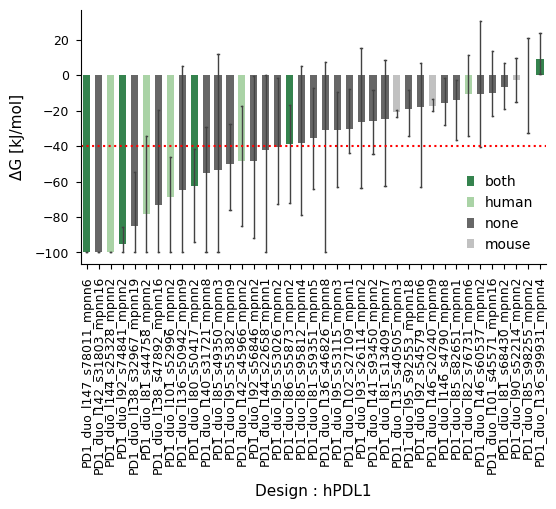

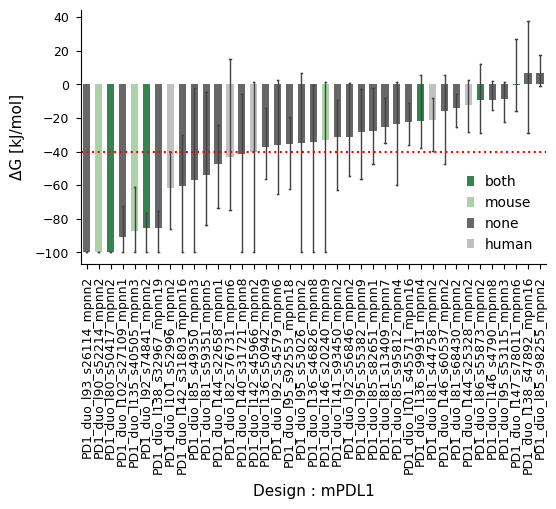

In [4]:
pal = ['#289049', '#a4da9e', '#676767', '#c1c1c1']
df_all = md_all.copy()
df_all = df_all[df_all['Experimental'] != 'unknown' ]

for name, df in df_all.groupby('target'):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.3))
    
    if name == 'human':
        exp_order = CategoricalDtype(['both', 'human', 'none', 'mouse'], ordered=True)
    else:
        exp_order = CategoricalDtype(['both', 'mouse', 'none', 'human'], ordered=True)
    df['Experimental'] = df['Experimental'].astype(exp_order)

    df_avg = df.groupby(['Design', 'batch'], as_index=False)['deltaG'].mean()
    df_best = df_avg.groupby('Design')['deltaG'].min().sort_values()
    order = df_best.index.tolist()

    sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,
                errwidth=1, capsize=0.1, width=0.6, order=order, palette=pal)

    plot_adjust_settings(f'Design : {name[0]}PDL1', 'ΔG [kJ/mol]')
    ax.legend(frameon=False, title='', handlelength=0.5, loc='lower right')
    ax.tick_params(axis='x', rotation=90)
    sns.despine()
    ax.axhline(-40, color='red', linestyle=':')
    #ax.set_ylim(-130, 10)

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/3245475238.py:23: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/3245475238.py:23: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,


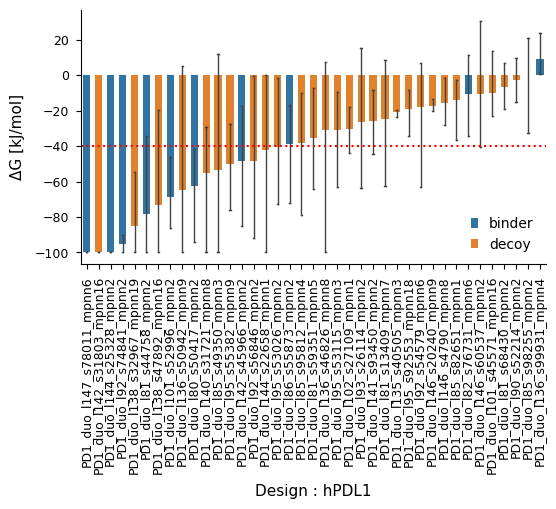

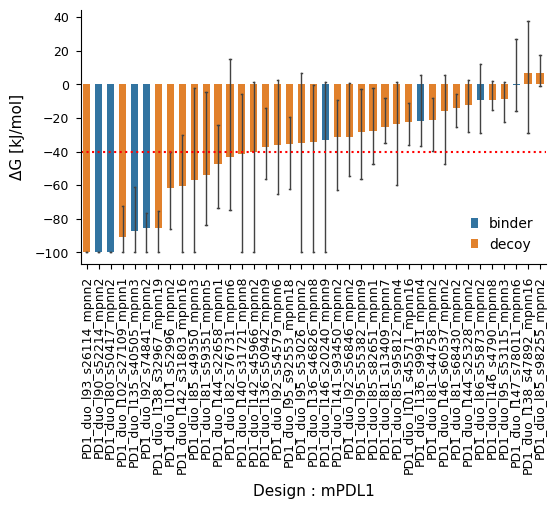

In [5]:
df_all = md_all.copy()
df_all = df_all[df_all['Experimental'] != 'unknown' ]

df_all['binary'] = np.select(
    [
        df_all['Experimental'].eq('none'),            # rule 1
        df_all['Experimental'].eq('both'),            # rule 2
        df_all['Experimental'].eq(df_all['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)


for name, df in df_all.groupby('target'):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.3))
    
    df = df.sort_values(by = 'binary')
    df_avg = df.groupby(['Design', 'batch'], as_index=False)['deltaG'].mean()
    df_best = df_avg.groupby('Design')['deltaG'].min().sort_values()
    order = df_best.index.tolist()

    sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,
                errwidth=1, capsize=0.1, width=0.6, order=order)

    plot_adjust_settings(f'Design : {name[0]}PDL1', 'ΔG [kJ/mol]')
    ax.legend(frameon=False, title='', handlelength=0.5, loc='lower right')
    ax.tick_params(axis='x', rotation=90)
    sns.despine()
    ax.axhline(-40, color='red', linestyle=':')
    #ax.set_ylim(-130, 10)
    

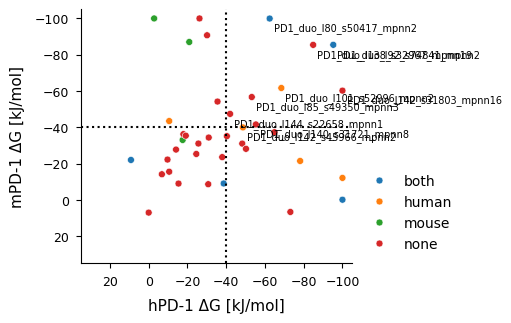

In [6]:
pal = ['#289049', '#a4da9e', '#676767', '#c1c1c1']
df = md_all.copy()
df = df_all[df_all['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
agg = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(mean_deltaG=('deltaG','mean'),
              std_deltaG=('deltaG','std'))
         .reset_index())

lst=[]
for name, df in agg.groupby('target'):
    df = df.rename(columns={
        'mean_deltaG': f'{name}_mean_deltaG',
        'std_deltaG':  f'{name}_std_deltaG'
    })
    df = df.drop(columns=['target'])
    lst.append(df)

df = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
exp_order = CategoricalDtype(['both', 'human', 'mouse', 'none'], ordered=True)
df['Experimental'] = df['Experimental'].astype(exp_order)
# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.scatterplot(df, x='human_mean_deltaG', y='mouse_mean_deltaG', hue='Experimental', ax=ax, s=25)

plot_adjust_settings('hPD-1 ΔG [kJ/mol]', 'mPD-1 ΔG [kJ/mol]')
ax.legend(bbox_to_anchor=(1,0.4), frameon=False, loc='upper left')
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(35, -105)
ax.set_ylim(35, -105)
sns.despine()
ax.axhline(-40, color='black', linestyle=':')
ax.axvline(-40, color='black', linestyle=':')

# labels
mask = (df['human_mean_deltaG'] < -39) & (df['mouse_mean_deltaG'] < -39)
for _, r in df[mask].iterrows():
    ax.annotate(r['Design'],
                (r['human_mean_deltaG'], r['mouse_mean_deltaG']),
                textcoords='offset points', xytext=(3, -3), ha='left', va='top',
                fontsize=7)

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/705058261.py:39: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: average_precision_score(g['y'], g['score']))


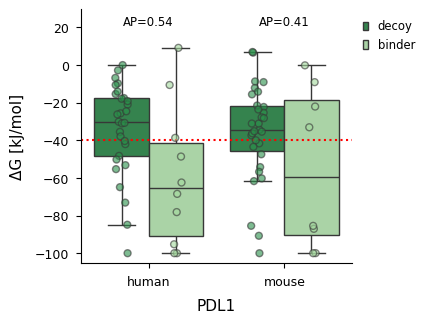

In [7]:
pal = ['#289049', '#a4da9e']
df = md_all.copy()
df = df[df['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
df = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(deltaG=('deltaG','mean'))
         .reset_index())

df['binary'] = np.select(
    [
        df['Experimental'].eq('none'),            # rule 1
        df['Experimental'].eq('both'),            # rule 2
        df['Experimental'].eq(df['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)

# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.boxplot(df, x='target', y='deltaG', hue='binary', ax=ax, showfliers=False, palette=pal)
sns.stripplot(df, x='target', y='deltaG', hue='binary', dodge=True,
              jitter=True, alpha=0.6, marker='o', linewidth=1, palette=pal)

plot_adjust_settings('PDL1', 'ΔG [kJ/mol]')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='', handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1,1))
ax.axhline(-40, color='red', linestyle=':')
sns.despine()

# average precision
from sklearn.metrics import average_precision_score

# compute AP per target (binder=positive), lower ΔG -> higher score
ap_by_target = (df.assign(y=(df['binary'] == 'binder').astype(int),
                          score=-df['deltaG'])
                  .groupby('target')
                  .apply(lambda g: average_precision_score(g['y'], g['score']))
                  .to_dict())

# after plotting:
ymax = ax.get_ylim()[1]
ax.set_ylim(ax.get_ylim()[0], ymax + 15)  # headroom
for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
    if lbl in ap_by_target:
        ax.text(x, ymax + 5, f"AP={ap_by_target[lbl]:.2f}",
                ha='center', va='bottom', fontsize='small')

0.20512820512820512


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/3158100971.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: average_precision_score(g['y'], g['score']))


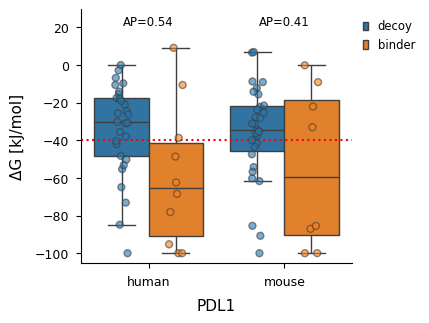

In [8]:
pal = ['#289049', '#a4da9e']
df = md_all.copy()
df = df[df['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
df = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(deltaG=('deltaG','mean'))
         .reset_index())

df['binary'] = np.select(
    [
        df['Experimental'].eq('none'),            # rule 1
        df['Experimental'].eq('both'),            # rule 2
        df['Experimental'].eq(df['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)

tmp = df[df['target'] == 'mouse']
binders = tmp[tmp['binary'] == 'binder']
print(len(binders)/len(tmp))

# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.boxplot(df, x='target', y='deltaG', hue='binary', ax=ax, showfliers=False)
sns.stripplot(df, x='target', y='deltaG', hue='binary', dodge=True,
              jitter=True, alpha=0.6, marker='o', linewidth=1)

plot_adjust_settings('PDL1', 'ΔG [kJ/mol]')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='', handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1,1))
ax.axhline(-40, color='red', linestyle=':')
sns.despine()

# average precision
from sklearn.metrics import average_precision_score

# compute AP per target (binder=positive), lower ΔG -> higher score
ap_by_target = (df.assign(y=(df['binary'] == 'binder').astype(int),
                          score=-df['deltaG'])
                  .groupby('target')
                  .apply(lambda g: average_precision_score(g['y'], g['score']))
                  .to_dict())

# after plotting:
ymax = ax.get_ylim()[1]
ax.set_ylim(ax.get_ylim()[0], ymax + 15)  # headroom
for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
    if lbl in ap_by_target:
        ax.text(x, ymax + 5, f"AP={ap_by_target[lbl]:.2f}",
                ha='center', va='bottom', fontsize='small')

# Reprediction

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/638311037.py:47: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(auc_score)
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/638311037.py:47: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(auc_score)
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/638311037.py:47: DeprecationWarning: DataFrameGroupBy

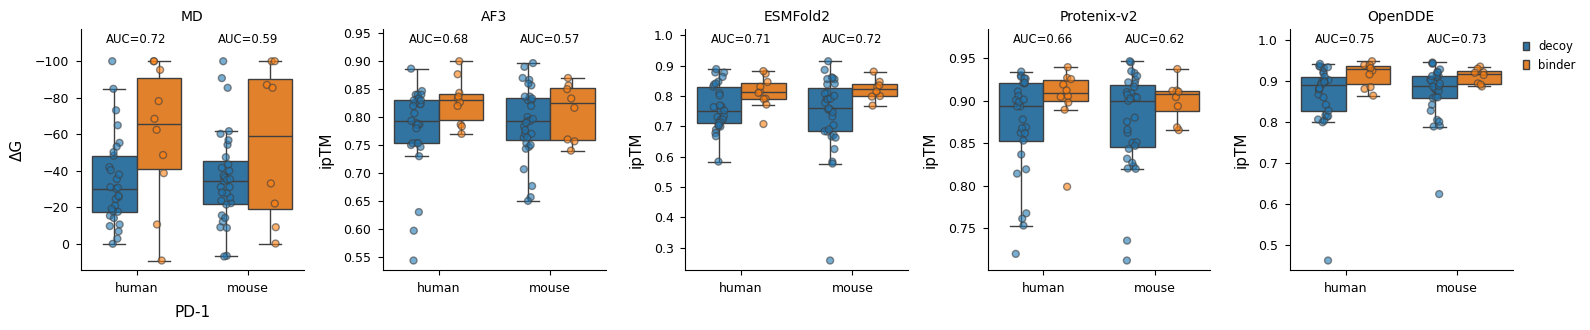

In [9]:
# ---- MD: deltaG (averaged over replicas), lower = better -----------------
md = md_all[md_all['Experimental'] != 'unknown']
md = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
        .agg(deltaG=('deltaG', 'mean')))
md['binary'] = np.select(
    [md['Experimental'].eq('none'),
     md['Experimental'].eq('both'),
     md['Experimental'].eq(md['target'])],
    ['decoy', 'binder', 'binder'], default='decoy')

# panel spec: (dataframe, value column, ylabel, higher_is_better, invert_y, title)
# predictors appear automatically once their metrics files exist
panels = [(md, 'deltaG', 'ΔG', False, True, 'MD')]
panels += [(load_iptm(m), 'iptm', 'ipTM', True, False, m) for m in METHODS[1:]]

def auc_score(g):
    """ROC-AUC; NaN if single-class."""
    y = (g['binary'] == 'binder').astype(int)
    if y.nunique() < 2:
        return np.nan
    return roc_auc_score(y, g['score'])

fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.4))

for i, (ax, (df, ycol, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='target', y=ycol, hue='binary', ax=ax, showfliers=False)
    sns.stripplot(df, x='target', y=ycol, hue='binary', dodge=True,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PD-1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)

    # legend only on the last panel, to the right
    if i == len(panels) - 1:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='',
                  handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.legend_.remove()

    # AUC per target (binder = positive)
    # score orientation: higher score -> more binder-like
    score = df[ycol] if higher_better else -df[ycol]
    auc_by_target = (df.assign(score=score)
                       .groupby('target')
                       .apply(auc_score)
                       .to_dict())

    if invert_y:
        ax.invert_yaxis()                       # more negative (good) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.10 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ytext = yhi - 0.25 * pad
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.10 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ytext = ymax + 0.25 * pad

    for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
        if lbl in auc_by_target and np.isfinite(auc_by_target[lbl]):
            ax.text(x, ytext, f"AUC={auc_by_target[lbl]:.2f}",
                    ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()

,method,AUC,lo,hi
0,MD,0.662,0.461,0.856
1,AF3,0.627,0.463,0.788
2,ESMFold2,0.713,0.594,0.824
3,Protenix-v2,0.641,0.489,0.778
4,OpenDDE,0.739,0.602,0.856


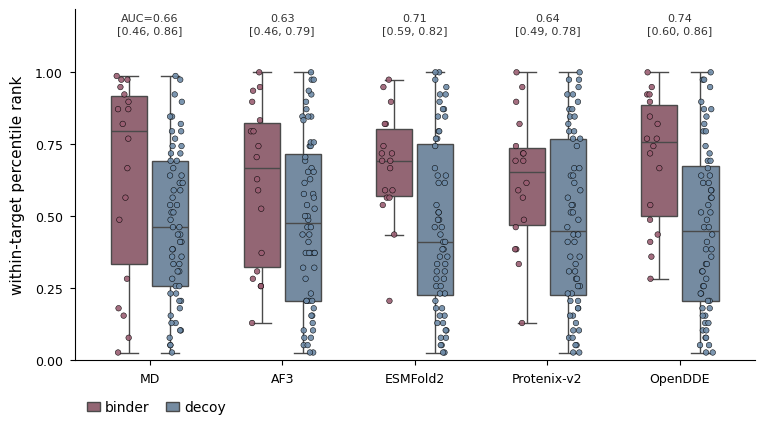

In [10]:
# ---- pooled panel: within-target percentile rank -------------------------
PAL = {"binder": "#9A5E72", "decoy": "#6E8BA8"}
N_BOOT, SEED = 4000, 0

md = md_all[md_all['Experimental'] != 'unknown']
md = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
        .agg(deltaG=('deltaG', 'mean')))
md['binary'] = np.select(
    [md['Experimental'].eq('none'),
     md['Experimental'].eq('both'),
     md['Experimental'].eq(md['target'])],
    ['decoy', 'binder', 'binder'], default='decoy')
md = md.assign(method='MD', score=-md['deltaG'])

cols = ['Design', 'target', 'Experimental', 'binary', 'method', 'score']
long = pd.concat([md[cols]] +
                 [load_iptm(m).assign(method=m, score=lambda d: d['iptm'])[cols]
                  for m in METHODS[1:]], ignore_index=True)
long['y']    = (long.binary == 'binder').astype(int)
long['rank'] = long.groupby(['method', 'target'])['score'].rank(pct=True)

def rank_auc(g):
    """AUC on within-target percentile ranks, recomputed for whatever rows are passed."""
    return roc_auc_score(g.y, g.groupby('target')['score'].rank(pct=True))

def rank_auc_ci(g, n_boot=N_BOOT, seed=SEED):
    """Percentile bootstrap resampling DESIGNS, since each appears in both targets."""
    rng       = np.random.default_rng(seed)
    designs   = g.Design.unique()
    by_design = {d: sub for d, sub in g.groupby('Design')}
    v = []
    for _ in range(n_boot):
        b = pd.concat([by_design[d] for d in rng.choice(designs, len(designs), replace=True)])
        if b.y.nunique() < 2:
            continue
        v.append(rank_auc(b))
    return np.percentile(v, [2.5, 97.5])

stats = pd.DataFrame([
    dict(method=m, AUC=rank_auc(long[long.method == m]),
         **dict(zip(['lo', 'hi'], rank_auc_ci(long[long.method == m]))))
    for m in METHODS])
display(stats.round(3))

kw = dict(x='method', y='rank', hue='binary', order=METHODS,
          hue_order=['binder', 'decoy'], dodge=True, palette=PAL)

fig, ax = plt.subplots(figsize=(1.45 * len(METHODS) + 0.5, 4.4))
sns.boxplot(long, **kw, showfliers=False, width=0.62, gap=0.12, ax=ax)
sns.stripplot(long, **kw, size=4, edgecolor='black', linewidth=0.4,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.22)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, r in stats.iterrows():
    txt = (f"AUC={r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]" if i == 0
           else f"{r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]")
    ax.text(i, 0.99, txt, transform=trans, ha='center', va='top',
            fontsize=8, linespacing=1.3, color='#333333')

plot_adjust_settings('', 'within-target percentile rank', ax=ax)
ax.margins(x=0.06)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc='upper left', bbox_to_anchor=(0.0, -0.08), ncol=2,
          frameon=False, handlelength=0.9, handletextpad=0.4, columnspacing=1.2)

sns.despine(fig)
fig.tight_layout()


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/1810699743.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/1810699743.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/1810699743.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/v

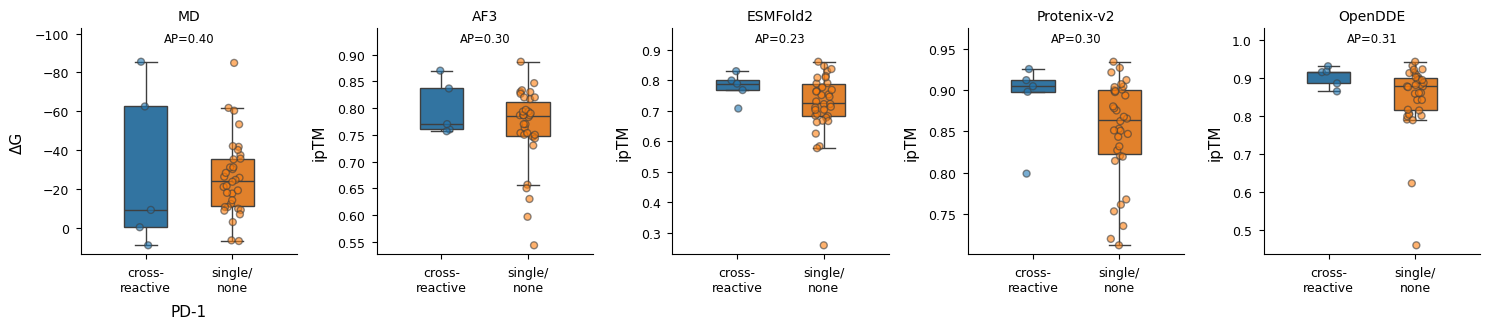

In [11]:
order = ['cross-reactive', 'single/none']
pal = {'cross-reactive': '#1f77b4', 'single/none': '#ff7f0e'}

# ---- MD: worst-target ΔG (averaged over replicas), lower = better ---------
md = md_all[md_all['Experimental'] != 'unknown']
agg = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
         .agg(mean_deltaG=('deltaG', 'mean')))
lst = []
for name, g in agg.groupby('target'):
    lst.append(g.rename(columns={'mean_deltaG': f'{name}_mean_deltaG'}).drop(columns=['target']))
md = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
md['group'] = np.where(md['Experimental'].eq('both'), 'cross-reactive', 'single/none')
md['value'] = md[['human_mean_deltaG', 'mouse_mean_deltaG']].max(axis=1)  # bottleneck target

# panel spec: (dataframe, ylabel, higher_is_better, invert_y, title)
panels = [(md, 'ΔG', False, True, 'MD')]
panels += [(load_iptm_min(m), 'ipTM', True, False, m) for m in METHODS[1:]]

fig, axes = plt.subplots(1, len(panels), figsize=(3.0 * len(panels), 3.4))

for i, (ax, (df, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='group', y='value', order=order, palette=pal,
                width=0.5, showfliers=False, ax=ax)
    sns.stripplot(df, x='group', y='value', order=order, palette=pal,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PD-1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([g.replace('-', '-\n').replace('/', '/\n') for g in order])

    # average precision (cross-reactive = positive)
    score = df['value'] if higher_better else -df['value']
    ap = average_precision_score((df['group'] == 'cross-reactive').astype(int), score)

    if invert_y:
        ax.invert_yaxis()                       # more negative (better) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.12 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ax.text(0.5, yhi - 0.3 * pad, f"AP={ap:.2f}", ha='center', va='bottom', fontsize='small')
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.12 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ax.text(0.5, ymax + 0.3 * pad, f"AP={ap:.2f}", ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/453037886.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/453037886.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/453037886.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_87340/453037886.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(df, x='group', y='value', order=order, palette=pal,
/va

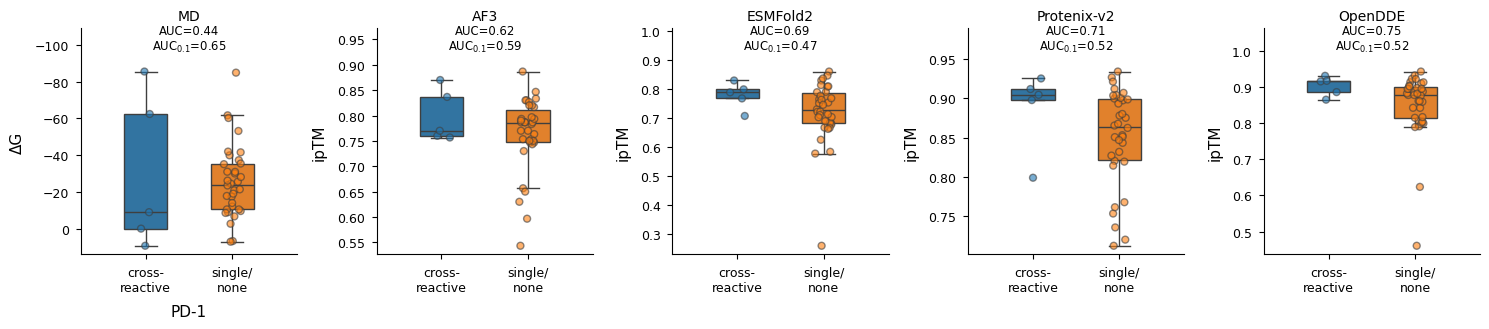

In [12]:
order = ['cross-reactive', 'single/none']
pal = {'cross-reactive': '#1f77b4', 'single/none': '#ff7f0e'}

# ---- MD: worst-target ΔG (averaged over replicas), lower = better ---------
md = md_all[md_all['Experimental'] != 'unknown']
agg = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
         .agg(mean_deltaG=('deltaG', 'mean')))
lst = []
for name, g in agg.groupby('target'):
    lst.append(g.rename(columns={'mean_deltaG': f'{name}_mean_deltaG'}).drop(columns=['target']))
md = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
md['group'] = np.where(md['Experimental'].eq('both'), 'cross-reactive', 'single/none')
md['value'] = md[['human_mean_deltaG', 'mouse_mean_deltaG']].max(axis=1)  # bottleneck target

# panel spec: (dataframe, ylabel, higher_is_better, invert_y, title)
panels = [(md, 'ΔG', False, True, 'MD')]
panels += [(load_iptm_min(m), 'ipTM', True, False, m) for m in METHODS[1:]]

fig, axes = plt.subplots(1, len(panels), figsize=(3.0 * len(panels), 3.4))

for i, (ax, (df, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='group', y='value', order=order, palette=pal,
                width=0.5, showfliers=False, ax=ax)
    sns.stripplot(df, x='group', y='value', order=order, palette=pal,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PD-1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([g.replace('-', '-\n').replace('/', '/\n') for g in order])

    # AUC + standardized partial AUC (FPR<=0.1); cross-reactive = positive
    score = df['value'] if higher_better else -df['value']
    y = (df['group'] == 'cross-reactive').astype(int)
    if y.nunique() < 2:
        auc = auc01 = np.nan
    else:
        auc = roc_auc_score(y, score)
        auc01 = roc_auc_score(y, score, max_fpr=0.1)
    txt = f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}"

    if invert_y:
        ax.invert_yaxis()                       # more negative (better) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.18 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ax.text(0.5, yhi - 0.25 * pad, txt, ha='center', va='bottom', fontsize='small')
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.18 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ax.text(0.5, ymax + 0.25 * pad, txt, ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()

# Continuous readout: Spearman against BLI response

The binary analysis above collapses a continuous measurement into binder/decoy
and then drops the borderline designs. That throws away the thing we actually
care about: whether the score tracks binding *strength*. Here the score is
correlated directly against the BLI response at 1 uM, over all 39 designs with
MD data and with no label-based exclusions.

Two details matter.

**Censoring.** Non-binders sit in a tight noise band (-0.05 +- 0.02, max 0.021)
while responders run from 0.15 to 2.4. Ranking within the noise band is
meaningless, so BLI is censored at `BLI_FLOOR` and all non-responders become
tied. Without this, Spearman spends most of its power ordering instrument noise.
The `rho_uncens` column shows what happens if you do not censor; the floor sweep
at the end shows the choice of floor does not drive the result.

**Direction.** Score is always higher = better, so `-deltaG` for MD and ipTM for
the predictors. A positive rho means the method ranks stronger binders higher.

`rho_responders` is the correlation among responders only, i.e. given that a
design binds, does the score track how well. It is reported because it separates
two different abilities, but n is 10-11 and it was computed after seeing the
main result, so it is observational.

In [13]:
# ---- Spearman: score vs continuous BLI response -------------------------
from scipy.stats import spearmanr

N_BOOT, SEED = 4000, 0

def _rho_ci(g, scol='score', bcol='bli_cens', n_boot=N_BOOT, seed=SEED):
    """Percentile bootstrap over DESIGNS (a design contributes both targets)."""
    rng, by = np.random.default_rng(seed), {k: s for k, s in g.groupby('Design')}
    keys, v = list(by), []
    for _ in range(n_boot):
        b = pd.concat([by[k] for k in rng.choice(keys, len(keys), replace=True)])
        if b[bcol].nunique() < 2 or b[scol].nunique() < 2:
            continue
        v.append(spearmanr(b[scol], b[bcol]).statistic)
    return np.percentile(v, [2.5, 97.5])

dat = score_long().merge(bli_long, on=['Design', 'target'], how='inner')

# --- per target ----------------------------------------------------------
rows = []
for (m, t), g in dat.groupby(['method', 'target']):
    r = g[g.responder]
    s = spearmanr(g.score, g.bli_cens)
    lo, hi = _rho_ci(g)
    rows.append(dict(method=m, target=t, n=len(g), n_resp=int(g.responder.sum()),
                     rho=s.statistic, p=s.pvalue, lo=lo, hi=hi,
                     rho_uncens=spearmanr(g.score, g.bli).statistic,
                     rho_responders=spearmanr(r.score, r.bli).statistic if len(r) > 2 else np.nan))
per_target = pd.DataFrame(rows)

# --- cross-reactivity: worst of the two targets --------------------------
w = dat.pivot_table(index=['Design', 'method'], columns='target',
                    values=['score', 'bli', 'bli_cens']).reset_index()
w.columns = ['_'.join(c for c in col if c) for col in w.columns]
w = w.dropna()
w['score'] = w[[f'score_{t}' for t in TARGETS]].min(axis=1)       # bottleneck target
w['bli_cens'] = w[[f'bli_cens_{t}' for t in TARGETS]].min(axis=1)
w['responder'] = w.bli_cens > BLI_FLOOR

rows = []
for m, g in w.groupby('method'):
    s = spearmanr(g.score, g.bli_cens)
    lo, hi = _rho_ci(g)
    rows.append(dict(method=m, n=len(g), n_resp=int(g.responder.sum()),
                     rho=s.statistic, p=s.pvalue, lo=lo, hi=hi))
cross = pd.DataFrame(rows)

def _show(df, title):
    d = df.copy()
    d['95% CI'] = [f'[{a:.2f}, {b:.2f}]' for a, b in zip(d.lo, d.hi)]
    print(title)
    print(d.drop(columns=['lo', 'hi']).round(3).to_string(index=False), '\n')

_show(per_target, f'per target, BLI censored at {BLI_FLOOR}')
_show(cross, 'cross-reactivity, worst-of-two score vs worst-of-two BLI')

# --- floor sensitivity ---------------------------------------------------
print('floor sweep, cross-reactivity rho')
for f in [0.02, 0.05, 0.10, 0.15]:
    cells = []
    for m, g in w.groupby('method'):
        b = np.minimum(*[g[f'bli_{t}'].clip(lower=f) for t in TARGETS])
        cells.append(f'{m} {spearmanr(g.score, b).statistic:+.2f}')
    print(f'  {f:>5}   ' + '   '.join(cells))

per target, BLI censored at 0.05
     method target  n  n_resp   rho     p  rho_uncens  rho_responders        95% CI
        AF3  human 39      11 0.322 0.045       0.209           0.237  [0.01, 0.58]
        AF3  mouse 39      10 0.240 0.141       0.277          -0.182 [-0.10, 0.54]
   ESMFold2  human 39      11 0.340 0.034       0.313           0.164  [0.06, 0.59]
   ESMFold2  mouse 39      10 0.418 0.008       0.368          -0.273  [0.17, 0.62]
         MD  human 39      11 0.427 0.007       0.214           0.442  [0.10, 0.67]
         MD  mouse 39      10 0.080 0.626       0.120           0.503 [-0.32, 0.46]
    OpenDDE  human 39      11 0.399 0.012       0.467           0.164  [0.10, 0.64]
    OpenDDE  mouse 39      10 0.283 0.081       0.192           0.297 [-0.00, 0.54]
Protenix-v2  human 39      11 0.269 0.098       0.325           0.618 [-0.05, 0.54]
Protenix-v2  mouse 39      10 0.306 0.058       0.329          -0.248  [0.03, 0.54] 

cross-reactivity, worst-of-two score vs w

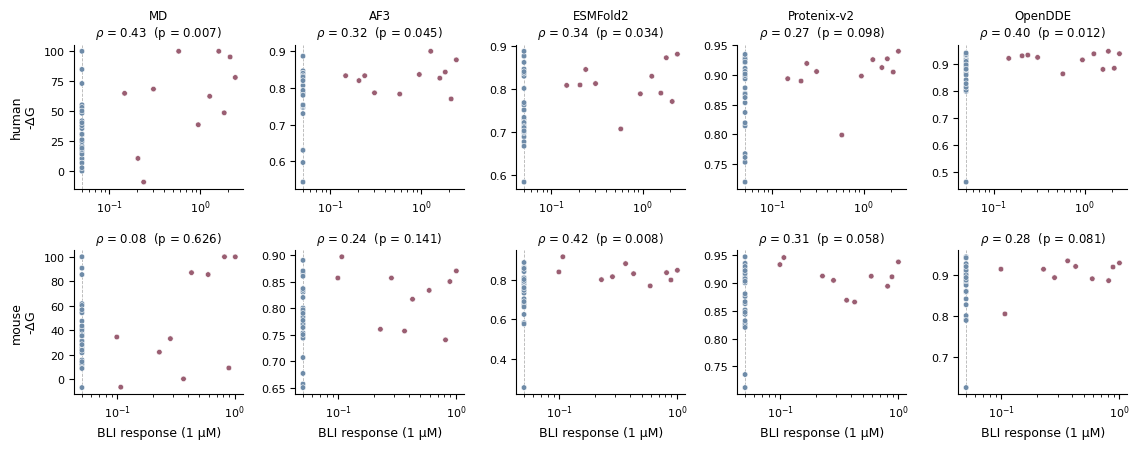

In [14]:
# ---- scatter: score vs BLI response -------------------------------------
PAL_R = {True: '#9A5E72', False: '#6E8BA8'}
panels = [(t, dat[dat.target == t]) for t in TARGETS]

fig, axes = plt.subplots(len(panels), len(METHODS),
                         figsize=(2.3 * len(METHODS), 2.3 * len(panels)),
                         sharex='row')
axes = np.atleast_2d(axes)

for i, (row_name, src) in enumerate(panels):
    for j, m in enumerate(METHODS):
        ax = axes[i, j]
        g = src[src.method == m]
        ax.scatter(g.bli_cens, g.score, s=16, linewidth=0.4, edgecolor='w',
                   c=g.responder.map(PAL_R))
        ax.set_xscale('log')
        ax.axvline(BLI_FLOOR, color='0.7', lw=0.6, ls='--', zorder=0)
        s = spearmanr(g.score, g.bli_cens)
        ax.set_title(f'{m}\n' r'$\rho$ = ' f'{s.statistic:.2f}  (p = {s.pvalue:.3f})'
                     if i == 0 else r'$\rho$ = ' f'{s.statistic:.2f}  (p = {s.pvalue:.3f})',
                     fontsize=8.5)
        if j == 0:
            ax.set_ylabel(f'{row_name}\n' + ('-' + r'$\Delta$G' if m == 'MD' else 'score'),
                          fontsize=9)
        if i == len(panels) - 1:
            ax.set_xlabel('BLI response (1 µM)', fontsize=9)
        ax.tick_params(labelsize=8)

sns.despine(fig)
fig.tight_layout()
plt.show()

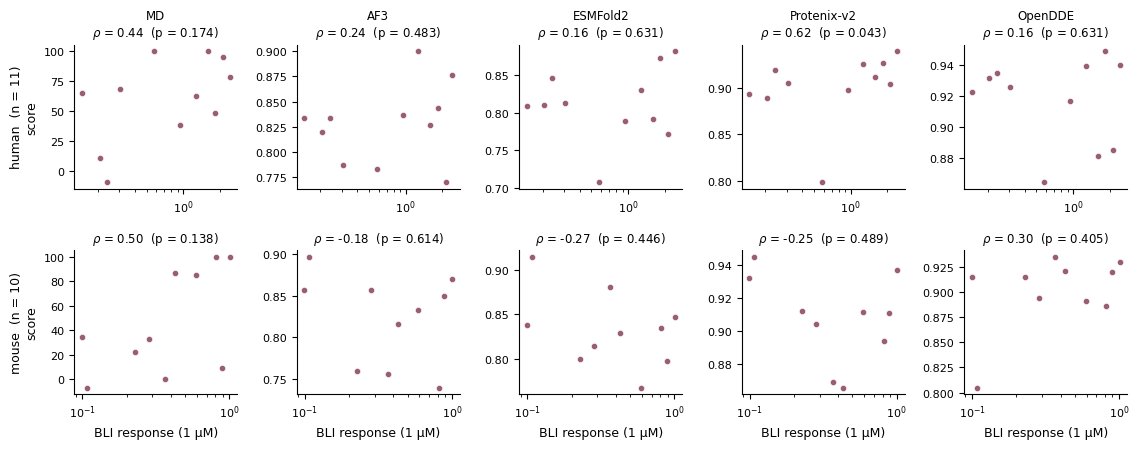

In [15]:
# ---- responders only: does the score track binding STRENGTH? ------------
# Restricted to designs with a real BLI response, so the question is no longer
# "does it bind" but "given that it binds, how well". Uncensored BLI, since
# every point is above the noise floor. n = 10-11 per target, and this was
# looked at after the main result: observational, not a primary claim.
resp = dat[dat.responder]

fig, axes = plt.subplots(len(TARGETS), len(METHODS),
                         figsize=(2.3 * len(METHODS), 2.3 * len(TARGETS)),
                         sharex='row')
axes = np.atleast_2d(axes)

for i, t in enumerate(TARGETS):
    for j, m in enumerate(METHODS):
        ax = axes[i, j]
        g = resp[(resp.target == t) & (resp.method == m)]
        ax.scatter(g.bli, g.score, s=20, linewidth=0.4, edgecolor='w', c='#9A5E72')
        ax.set_xscale('log')
        s = spearmanr(g.score, g.bli)
        head = f'{m}\n' if i == 0 else ''
        ax.set_title(head + r'$\rho$ = ' f'{s.statistic:.2f}  (p = {s.pvalue:.3f})', fontsize=8.5)
        if j == 0:
            ax.set_ylabel(f'{t}  (n = {len(g)})\nscore', fontsize=9)
        if i == len(TARGETS) - 1:
            ax.set_xlabel('BLI response (1 µM)', fontsize=9)
        ax.tick_params(labelsize=8)

sns.despine(fig)
fig.tight_layout()
plt.show()